# SEM-Beam-Gym: может ли RL с магнитометром и акселерометром повысить качество снимка SEM?

Итоговый проект по курсу "Обучение с подкреплением", выбран трек 2 (собственная предметная область).

Этот ноутбук - полная демонстрация проекта: модель помех, среда, бейзлайны, обучение PPO,
оценка, проверка гипотез, поведение агентов и выводы. Подробный отчёт - [README.md](../README.md),
код - пакет [`src/sem_beam_gym`](../src/sem_beam_gym).

**Постановка задачи.** В задачах связанных с анализом образцов микроэлектроники (HRE, верификация) обязательным компонентом является растровый электронный микроскоп (SEM). Упрощенно принцип его работы выглядит следующим образом:
1. Образец для исследования находится в вакууме в специальной камере.
2. Источник электронов (электронная пушка) формирует пучок электронов с заданной энергетикой.
3. Пара ЭМ катушек, управляемых программной частью, формирует поле, отклоняющее электронный луч и, таким образом, формирует "область видимости" микроскопа.  
4. После взаимодействия пучка электронов с кристаллической решеткой образца специальная система микроскопа формирует изображение в градациях серого.

На весь описанный процесс оказывают побочное влияние различные шумы. В данном проекте нет цели максимально точно описать помехи, поэтому для простоты мною взяты 2 самых очевидных вида: вибрационные и ЭМ помехи от сети питания.

Вибрационная помеха выражается в наличии ненулевой скорости столика микроскопа, относительно фокальной оси микроскопа. В качестве источников взяты:
- фоновые вибрационные шумы самого здания (работа климатических установок)
- шаги в коридоре
- движение 2-х лифтов в здании
- работа форвакуумного насоса в соседнем помещени (неотъемлемая часть вакуумной системы микроскопа)  

Итоговая вибрационная помеха рассматривается в различных сценариях, но по сути является суперпозицией скоростей от всех источников. Для упрощения модели в качестве направления вибрационной помехи выбрана одна ось - X - смещение вдоль строки сканирования электронного луча (как наиболее заметное проявление помехи).

Электромагнитная помеха - это наводки от 50Гц сети и ее гармоник с учетом небольшой дивиации частоты сети.

Условимся, что микроскоп снимает кадр 2000 x 2000 px построчно, типичное время набора
кадра - 40 с (10 мкс на пиксель). Внешние помехи - электромагнитная от сети 50 Гц и вибрация смещают луч относительно образца, и снимок искажается. Агент раз в 0.5 мс подаёт
коррекцию на отклоняющую систему, чтобы скомпенсировать смещение.

**Мотивация.** На установке нет ни магнитометра, ни акселерометра. Прежде чем их ставить, нужно
понять, даст ли регулятор на их сигналах выигрыш, при каких режимах съёмки и при каких источниках
вибрации. Помехи и сигналы датчиков синтетические: работа отвечает на вопрос "при каких условиях
это имеет смысл", а не доказывает выигрыш на конкретной установке.

**Исследовательский вопрос.** Насколько снижается ошибка позиции луча, если RL-агент получает
сигналы магнитометра и акселерометра, по сравнению с агентом, который видит только сам кадр?
Как выигрыш зависит от режима съёмки и от природы вибрации?

**Гипотезы** (зафиксированы до обучения):

| | Гипотеза |
|---|---|
| **H1** (основная) | Датчики снижают ошибку в типичном (10 мкс/px) и медленном режимах во всех сценариях: обратная связь по изображению запаздывает на строку, а помеха сети при строке 20 мс по изображению не видна. |
| **H2** | На быстрой развёртке выигрыш от датчиков мал для тонального насоса (он предсказуем по изображению) и велик для импульсных источников (шаги, лифты). |
| **H3** | Агент с "тихого" сценария теряет качество на сценариях с событиями, а агент, обученный на сценарии "рабочий день", близок к лучшему везде. |
| **H4** | Связь "ускорение $\to$ смещение луча" линейна, поэтому линейный фильтр на датчиках близок к RL + датчики. |
| **H5** | Domain randomization немного ($\leq$ 15 %) уступает специалисту, но превосходит худшего "чужого" специалиста и устойчивее к шуму акселерометра. |

**Метрика** - RMS истинной ошибки позиции луча, нм (1 px = 5 нм).  
**Фактор** - наблюдение (с датчиками / без), всё остальное одинаково: среда, награда, сеть, PPO, бюджет 1M шагов, оценка.

## 0. Настройка

Запуск: `uv sync`, затем открыть ноутбук с ядром из `.venv` (VS Code, Zed, Jupyter) или выполнить
целиком: `uv run jupyter nbconvert --to notebook --execute --inplace notebooks/pipeline.ipynb`.

По умолчанию ноутбук **не переобучает** 36 агентов ($\approx$ 1 ч на 8 потоках) и не пересчитывает
матрицу оценки ($\approx$ 15 мин), а читает сохранённые `runs/` и `results/eval.csv`. Всё остальное считается здесь, вживую ($\approx$ 5 мин):
- моделирование помех
- бейзлайны
- короткое демонстрационное обучение
- проверка линейного фильтра
- поведение агентов

Флаги ниже включают полный пересчёт.

In [1]:
import subprocess
import sys
import tempfile
import time
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from sem_beam_gym import baselines, evaluate, gallery, linear_memory, plots, train, visualize
from sem_beam_gym.disturbances import Ambient, Footsteps, Isolation, Sensors, Site
from sem_beam_gym.env import SIGMA_REF, BeamEnv
from sem_beam_gym.paths import RESULTS, ROOT, RUNS
from sem_beam_gym.scenarios import TRAIN_SCENARIOS, Scenario, simulate

RUN_TRAINING = True    # True: заново обучить все 36 агентов (~ 1 ч на 8 потоках)
RUN_EVALUATION = True  # True: заново посчитать матрицу оценки (~ 15 мин)

plt.rcParams["figure.dpi"] = 80
pd.set_option("display.precision", 2)
L = plots.LABEL
SC = plots.SC_LABEL  # подписи методов и сценариев


def show(df, caption=None):
    # таблица в Markdown: читается и в Jupyter, и на GitHub
    if caption:
        display(Markdown(f"**{caption}**"))
    display(Markdown(df.to_markdown(floatfmt=".2f")))


print("корень проекта:", ROOT.parts[-1])
print("обученных агентов:", len(list(RUNS.glob("*/*/model.zip"))), "из 36")
print("результаты оценки:", (RESULTS / "eval.csv").exists())

корень проекта: 26-rl-final-task
обученных агентов: 36 из 36
результаты оценки: True


## 1. Модель помех

Проект задуман как **среда для исследователей**: сценарий помех собирается из физических блоков
([`disturbances.py`](../src/sem_beam_gym/disturbances.py)), и каждый может смоделировать свою
лабораторию. Цепочка вибрации:

```
источники --> виброскорость перекрытия v(t), мкм/с (вклады складываются, критерии VC)
          --> ускорение a = dv/dt --> виброизоляция (опц.) --> ускорение рамы --> акселерометр
          --> мода колонны 110 Гц, zeta = 0.05 --> смещение луча, нм
```

Источники: фон здания, форвакуумный насос в соседней комнате ($\approx$ 24 Гц и гармоники),
2 лифта в 6-этажном здании (вызовы - пуассоновский поток 40/ч, разгон-движение-торможение,
двери), шаги в коридоре (пешеходы - пуассоновский поток, удары возбуждают моду перекрытия 12 Гц).
Микроскоп - на 5-м этаже. Сеть: гармоники 50/150/250 Гц с медленной модуляцией, магнитометр
видит их с другим усилением и фазой.

Пять типичных сценариев: **тихо** (только фон), **насос**, **лифты**, **шаги**, **рабочий день**
(всё сразу). Ниже - 120 с каждого сценария: виброскорость перекрытия с линиями критериев VC,
смещение луча и спектр.

VC - Vibration Criteria (критерии вибрации), отраслевой стандарт для помещений с чувствительным оборудованием (SEM, литография, чистые комнаты и т.п.).

| Класс | Значение |
|-|-|
|VC-A| 50 мкм/с |
|VC-C| 12.5 мкм/с |
|VC-E| 3.1 мкм/c |

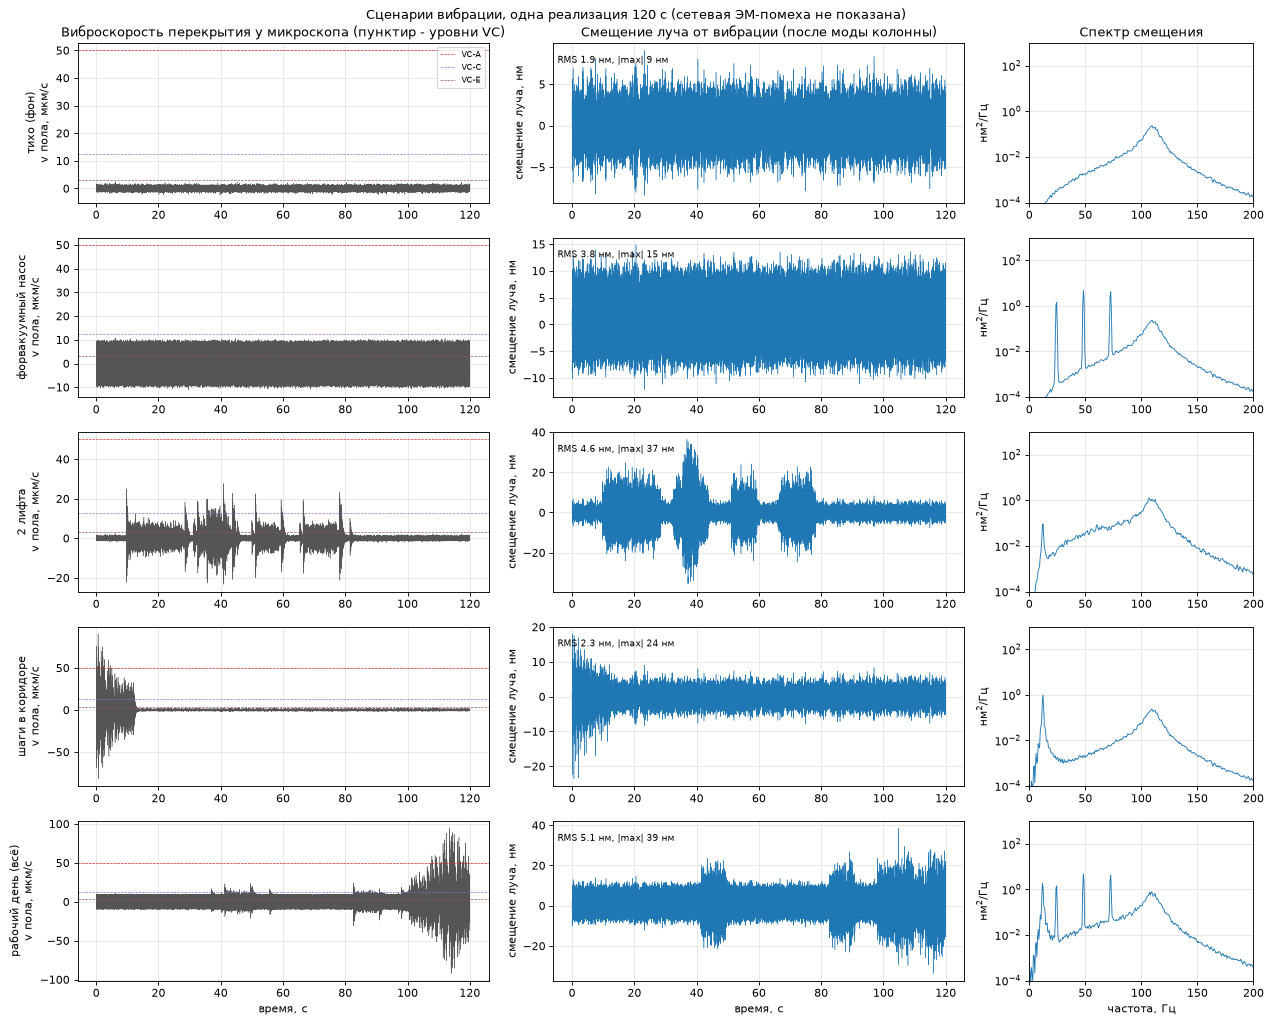

In [2]:
gallery.FIGURES.mkdir(exist_ok=True)
gallery.scenarios_figure();

Лифты - самый "событийный" источник: каждый рейс - разгон, движение, торможение и двери.
Расписание за 30 минут, сгенерированное пуассоновским потоком вызовов:

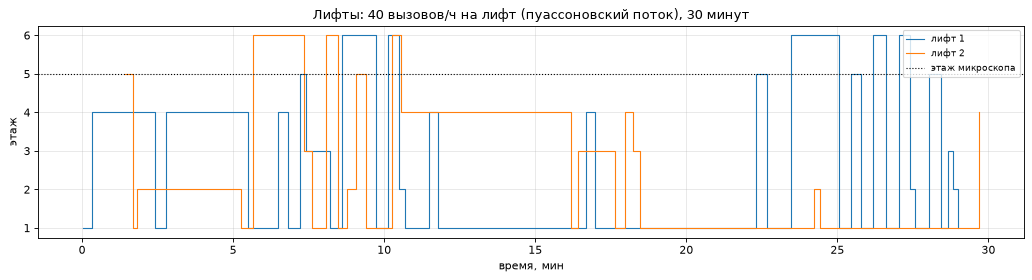

In [3]:
gallery.elevators_figure();

**Свой сценарий.** Любой сценарий собирается из блоков, а свой источник - это любой объект с
методом `floor_velocity(rng, n, fs, site)`, возвращающим виброскорость, мкм/с. Пример: меньшее
здание, микроскоп на пневмоопорах, дешёвый MEMS-акселерометр и компрессор, работающий 4 минуты из 10.
Для сравнения - та же лаборатория без пневмоопор.

In [4]:
class Compressor:
    """Свой источник вибрации: компрессор 49 Гц, работающий 4 минуты из 10."""

    def floor_velocity(self, rng, n, fs, site):
        # Синусоида 49 Гц, включённая по расписанию - самый простой источник, на котором видно
        # и тон, и включение/выключение. Достаточно одного метода floor_velocity, чтобы показать
        # протокол своего источника.
        t = np.arange(n) / fs
        on = (t % 600) < 240  # 4 минуты работы из 10
        return 5.0 * on * np.sin(2 * np.pi * 49.0 * t)


my = Scenario(
    "my_lab",
    vibration=(Ambient(rms_um_s=(1, 2)), Footsteps(walkers_per_hour=200, room_offset=2.0), Compressor()),
    site=Site(floors=3, microscope_floor=1, slab_freq=18.0),
    isolation=Isolation(freq=2.5),
    sensors=Sensors(acc_noise_ug=30),
)
for sc in (my, replace(my, name="my_lab без опор", isolation=Isolation())):
    dist = simulate(sc, np.random.default_rng(0), n=20_000 * 60, fs=20_000)  # 60 с
    print(f"{sc.name:16s} вибрация {np.std(dist.d_vib):6.3f} нм RMS, сеть {np.std(dist.d_mains):.1f} нм RMS")
env = BeamEnv(sensors=True, scenario=my)  # готовая среда для обучения и оценки
print("наблюдение:", env.observation_space.shape, " действие:", env.action_space)

my_lab           вибрация  0.447 нм RMS, сеть 8.4 нм RMS
my_lab без опор  вибрация 13.216 нм RMS, сеть 8.4 нм RMS
наблюдение: (72,)  действие: Box(-1.0, 1.0, (1,), float32)


Пневмоопоры с собственной частотой 2.5 Гц подавляют вибрацию выше $\approx 4$ Гц как $(2.5/f)^2$, и у
колонны (110 Гц) от неё почти ничего не остаётся: на пневмоопорах вибрационная задача фактически
исчезает и остаётся сетевая. Именно такие вопросы "а что в моей лаборатории" среда и позволяет
задавать до покупки оборудования.

## 2. Среда в терминах RL

[`env.py`](../src/sem_beam_gym/env.py), интерфейс Gymnasium. Одна ось (x - вдоль строки).

| | |
|---|---|
| **Состояние** (скрыто) | фазы и амплитуды сетевых гармоник, состояние мод колонны и перекрытия, положение лифтов, пешеходы, состояние катушки |
| **Наблюдение** | всегда: 16 последних действий, 16 последних сдвигов между строками, измеренных по изображению, своя коррекция строкой раньше, фаза сети (line sync), log dwell. С датчиками - ещё 16 отсчётов магнитометра и 16 акселерометра |
| **Действие** | смещение отклоняющей системы, непрерывное, $[-1, 1] \to \pm 100$ нм, катушка отрабатывает его с инерцией 0.1 мс |
| **Награда** | $-\overline{e^2} / (10\,\text{нм})^2$ за шаг, $e = d - u$ - истинная ошибка позиции луча |
| **Конец эпизода** | 512 шагов по 0.5 мс (0.256 с), только обрезание по времени (`truncated`). dwell случаен, 0.3...500 мкс/px |

**POMDP, а не MDP**: агент видит наблюдение, а не состояние. История из 16 шагов -
аналог стека кадров в Atari. Главный фактор эксперимента в этих терминах - *цена частичной
наблюдаемости*: оба агента решают один POMDP, но с разным наблюдением. Сеть в типичном режиме
(строка 20 мс = период сети) одинакова во всех строках, и без магнитометра её не видно ни при
какой длине истории.

**Награда** плотная и немедленная и равна самой цели, а не её косвенной оценке, поэтому
зазора для reward hacking в симуляторе нет. Цена - награда привилегированная: на установке
истинная ошибка неизвестна.

Посмотрим на наблюдение и проверим связь награды и метрики: $\mathrm{RMS} = 10\,\text{нм} \cdot \sqrt{-\bar r}$, где $\bar r$ - средняя награда за шаг.

In [5]:
env = BeamEnv(sensors=True, scenario="building")
obs, _ = env.reset(seed=0, options={"dwell": 10e-6})
layout = {
    "действия (16)": slice(0, 16),
    "сдвиги строк (16)": slice(16, 32),
    "коррекция строкой раньше, dwell": slice(32, 34),
    "фаза сети sin/cos (6)": env.idx_phase,
    "магнитометр + акселерометр (32)": env.idx_sensors,
}
for name, sl in layout.items():
    print(f"{name:34s} {sl.start:2d}..{sl.stop - 1:2d}  пример: {np.round(obs[sl][:3], 2)}")

rewards, done = [], False
while not done:
    obs, r, terminated, truncated, _ = env.step(np.zeros(1, dtype=np.float32))  # без коррекции
    rewards.append(r)
    done = terminated or truncated
m = env.episode_metrics()
print(f"\nэпизод без коррекции: {len(rewards)} шагов, награда за эпизод {sum(rewards):.0f}")
print(f"RMS из метрики: {m['rms_true']:.2f} нм.  10 * sqrt(-mean r) = {SIGMA_REF * np.sqrt(-np.mean(rewards)):.2f} нм")
print(f"в том числе вибрация {m['rms_vib']:.2f} нм, сеть {m['rms_mains']:.2f} нм RMS")

действия (16)                       0..15  пример: [0. 0. 0.]
сдвиги строк (16)                  16..31  пример: [-1.07 -1.04 -0.6 ]
коррекция строкой раньше, dwell    32..33  пример: [ 0.   -0.05]
фаза сети sin/cos (6)              34..39  пример: [ 0.46 -0.89  0.99]
магнитометр + акселерометр (32)    40..71  пример: [0.74 1.07 1.  ]

эпизод без коррекции: 512 шагов, награда за эпизод -658
RMS из метрики: 11.33 нм.  10 * sqrt(-mean r) = 11.33 нм
в том числе вибрация 8.91 нм, сеть 5.22 нм RMS


## 3. Бейзлайны

[`baselines.py`](../src/sem_beam_gym/baselines.py):

* **без коррекции** - нулевое действие (так снимают сейчас),
* **линейный фильтр + датчики** - классическое активное шумоподавление: команда - линейная
  комбинация тех же 16 + 16 отсчётов датчиков и фазы сети, коэффициенты - гребневая регрессия на
  200 эпизодах сценария обучения с известным смещением (те же привилегированные данные, что и в
  награде RL).

Подгоним фильтр на сценарии "рабочий день" и сравним с нулевой стратегией на 10 тестовых эпизодах:

In [6]:
t0 = time.time()
lin = baselines.LinearPolicy.fit("building")
print(f"фильтр подогнан за {time.time() - t0:.0f} с, {len(lin.w)} коэффициентов")

env = BeamEnv(sensors=True, scenario="building")
rows = []
for name, act in (("без коррекции", baselines.ZeroPolicy().act), ("линейный фильтр", lin.act)):
    for dw in (1e-6, 10e-6):
        rms = [train.rollout(env, act, evaluate.TEST_SEED + i, dw)["rms_true"] for i in range(10)]
        rows.append({"стратегия": name, "dwell, мкс": dw * 1e6, "RMS, нм": np.mean(rms)})
show(pd.DataFrame(rows).pivot(index="стратегия", columns="dwell, мкс", values="RMS, нм"),
     "RMS ошибки, нм, рабочий день, 10 тестовых эпизодов")

фильтр подогнан за 14 с, 39 коэффициентов


**RMS ошибки, нм, рабочий день, 10 тестовых эпизодов**

| стратегия       |   1.0 |   10.0 |
|:----------------|------:|-------:|
| без коррекции   |  9.94 |   9.41 |
| линейный фильтр |  3.76 |   3.42 |

## 4. Обучение PPO

**Почему PPO**: действие непрерывное, DQN выбирает только из конечного
набора действий. actor-critic с гауссовой политикой работает с непрерывным действием напрямую,
а клипирование отношения $\pi_{new}/\pi_{old}$ в PPO делает обновления устойчивыми. DP неприменимо: пространства непрерывны, модель переходов задана только симулятором.

Гиперпараметры ([`train.py`](../src/sem_beam_gym/train.py)):

In [7]:
desc = {
    "n_steps": "шагов rollout на среду (x 8 сред = 4096 переходов)",
    "batch_size": "мини-батч",
    "n_epochs": "эпох на одном rollout",
    "learning_rate": "постоянный: кривые выходят на плато задолго до конца",
    "gamma": r"награда немедленная, горизонт $1/(1-\gamma) = 10$ шагов",
    "gae_lambda": r"GAE: компромисс TD $\leftrightarrow$ MC",
    "clip_range": r"$\epsilon$ в $L^{CLIP}$",
    "ent_coef": r"исследование - за счёт $\sigma$ гауссовой политики",
    "policy_kwargs": r"MLP 128 x 128, раздельные актор и критик, $\log \sigma_0 = -1$ ($\sigma$ = 37 нм)",
}
show(pd.DataFrame({"значение": {k: str(v) for k, v in train.PPO_KW.items()}, "смысл": desc}))
print("сред:", train.N_ENVS, "| бюджет: 1M шагов на запуск | seed: 0, 1, 2 | условия: nosens, sens")

|               | значение                                       | смысл                                                                             |
|:--------------|:-----------------------------------------------|:----------------------------------------------------------------------------------|
| n_steps       | 512                                            | шагов rollout на среду (x 8 сред = 4096 переходов)                                |
| batch_size    | 512                                            | мини-батч                                                                         |
| n_epochs      | 10                                             | эпох на одном rollout                                                             |
| learning_rate | 0.0003                                         | постоянный: кривые выходят на плато задолго до конца                              |
| gamma         | 0.9                                            | награда немедленная, горизонт $1/(1-\gamma) = 10$ шагов                           |
| gae_lambda    | 0.95                                           | GAE: компромисс TD $\leftrightarrow$ MC                                           |
| clip_range    | 0.2                                            | $\epsilon$ в $L^{CLIP}$                                                           |
| ent_coef      | 0.0                                            | исследование - за счёт $\sigma$ гауссовой политики                                |
| policy_kwargs | {'net_arch': [128, 128], 'log_std_init': -1.0} | MLP 128 x 128, раздельные актор и критик, $\log \sigma_0 = -1$ ($\sigma$ = 37 нм) |

сред: 8 | бюджет: 1M шагов на запуск | seed: 0, 1, 2 | условия: nosens, sens


**Матрица обучения**: 6 сценариев обучения (5 типичных + domain randomization)  x  2 условия
(с датчиками / без)  x  3 seed = **36 запусков**, по 1M шагов. Domain randomization: в каждом эпизоде случайный набор источников, их амплитуды, частоты колонны и перекрытия, шумы
датчиков.

Чтобы показать, что обучение работает, обучим здесь же одного агента - "тихо", с датчиками,
100 тысяч шагов ($\approx$ 1 мин) - во временную папку и сравним с сохранённым полным запуском:

tmpb8oihbvg/quiet/sens_s0 {'step': 102400, 'val_rms': 5.204766947719742}
обучение: 76 с
общие точки валидации:
   step  val_rms_1M  val_rms_demo
     8        8.36          8.36
 50008        6.96          6.96
100008        5.51          5.51


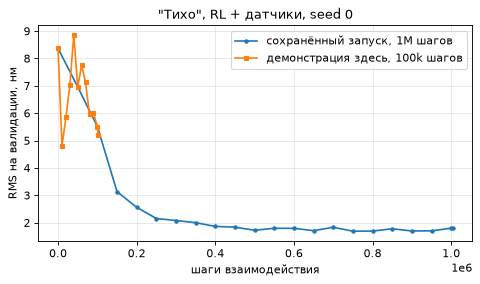

In [8]:
t0 = time.time()
with tempfile.TemporaryDirectory() as demo_root:  # демонстрационный агент не сохраняется
    short = pd.read_csv(train.train("quiet", "sens", seed=0, steps=100_000, root=demo_root) / "val.csv")
print(f"обучение: {time.time() - t0:.0f} с")

full = pd.read_csv(train.run_dir("quiet", "sens", 0) / "val.csv")
common = full.merge(short, on="step", suffixes=("_1M", "_demo"))
print("общие точки валидации:\n", common.to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(full.step, full.val_rms, "o-", ms=3, label="сохранённый запуск, 1M шагов")
ax.plot(short.step, short.val_rms, "s-", ms=4, label="демонстрация здесь, 100k шагов")
ax.set(xlabel="шаги взаимодействия", ylabel="RMS на валидации, нм", title='"Тихо", RL + датчики, seed 0')
ax.grid(alpha=0.3)
ax.legend();

В общих точках валидации (0, 50k и 100k шагов) значения совпадают до последнего знака: при том
же seed обучение воспроизводимо. Между точками валидационная кривая в начале обучения шумная -
политика ещё быстро меняется.
Полная матрица запускается одной командой (`uv run sem-beam`) или ячейкой ниже, если `RUN_TRAINING = True`.

In [9]:
if RUN_TRAINING:
    subprocess.run([sys.executable, "-m", "sem_beam_gym.main"], cwd=ROOT, check=True)
else:
    print("используем сохранённые агенты из", RUNS.parts[-1])

runs/quiet/nosens_s2 {'step': 1003520, 'val_rms': 6.368906324967341}
runs/quiet/nosens_s0 {'step': 1003520, 'val_rms': 6.686692458575673}
runs/quiet/nosens_s1 {'step': 1003520, 'val_rms': 6.352654729953979}
runs/quiet/sens_s1 {'step': 1003520, 'val_rms': 1.6944607532302924}
runs/quiet/sens_s2 {'step': 1003520, 'val_rms': 1.9258183905207773}
runs/pump/nosens_s0 {'step': 1003520, 'val_rms': 6.039097119254221}
runs/quiet/sens_s0 {'step': 1003520, 'val_rms': 1.8055991347441458}
runs/pump/nosens_s1 {'step': 1003520, 'val_rms': 5.917576120089025}
runs/pump/nosens_s2 {'step': 1003520, 'val_rms': 5.46704580557249}
runs/pump/sens_s1 {'step': 1003520, 'val_rms': 1.7870143498121802}
runs/pump/sens_s0 {'step': 1003520, 'val_rms': 1.7405491207142822}
runs/elevators/nosens_s1 {'step': 1003520, 'val_rms': 7.535707215245725}
runs/elevators/nosens_s0 {'step': 1003520, 'val_rms': 7.306478533253964}
runs/pump/sens_s2 {'step': 1003520, 'val_rms': 1.8059744131838902}
runs/elevators/nosens_s2 {'step': 10035

### Кривые обучения

Сверху - награда обучающих эпизодов: стохастическая политика, среднее по 8 средам, сглаживание. Снизу - RMS жадной политики на 16 фиксированных валидационных эпизодах (отдельные seed, не пересекаются с тестом). Полоса - СКО по 3 seed.

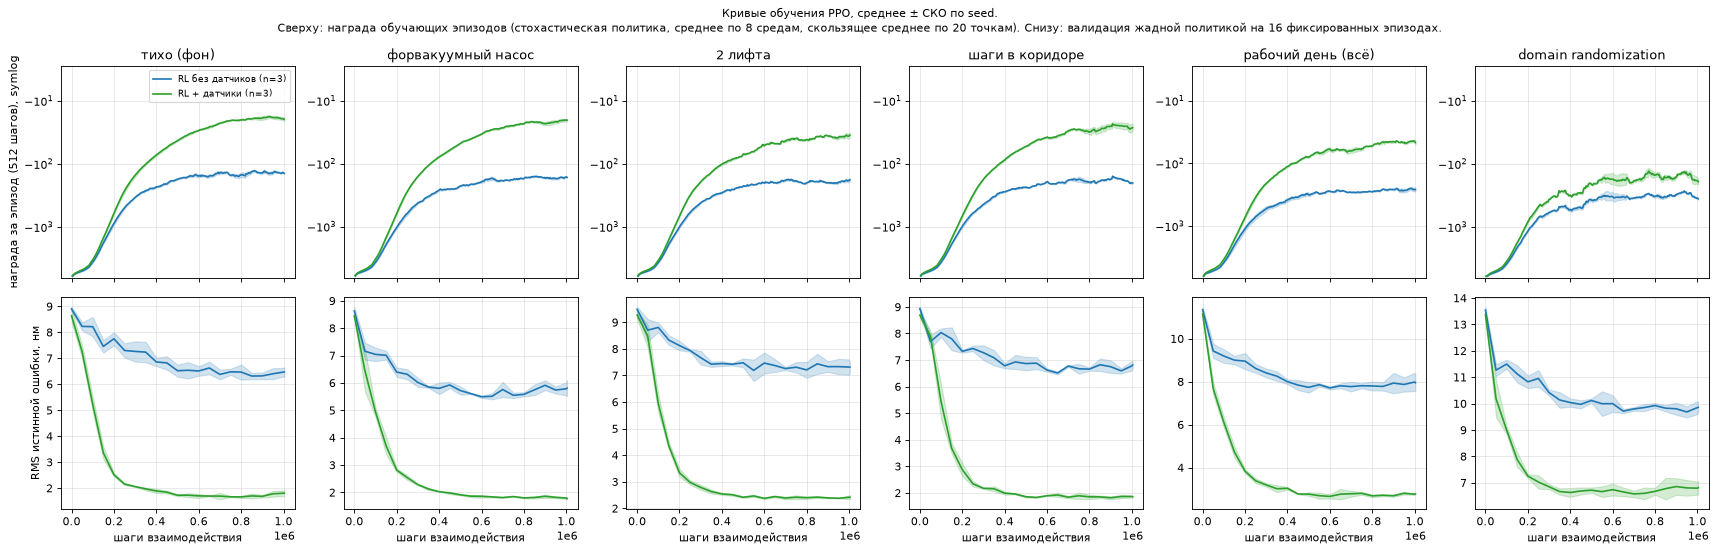

In [10]:
plots.learning_curves();

In [11]:
val = []
for sc in TRAIN_SCENARIOS:
    for cond, m in plots.COND.items():
        last = [pd.read_csv(r / "val.csv").val_rms.iloc[-1] for r in sorted((RUNS / sc).glob(f"{cond}_s*"))]
        val.append({"сценарий": SC[sc], "условие": L[m],
                    "RMS": f"{np.mean(last):.2f} {plots.PM} {np.std(last, ddof=1):.2f}"})
show(pd.DataFrame(val).pivot(index="сценарий", columns="условие", values="RMS"),
     rf"Валидация в конце обучения, нм (среднее {plots.PM} СКО по seed)")

**Валидация в конце обучения, нм (среднее $\pm$ СКО по seed)**

| сценарий             | RL + датчики    | RL без датчиков   |
|:---------------------|:----------------|:------------------|
| 2 лифта              | 2.42 $\pm$ 0.08 | 7.31 $\pm$ 0.22   |
| domain randomization | 6.81 $\pm$ 0.26 | 9.86 $\pm$ 0.19   |
| рабочий день (всё)   | 2.78 $\pm$ 0.05 | 7.95 $\pm$ 0.37   |
| тихо (фон)           | 1.81 $\pm$ 0.12 | 6.47 $\pm$ 0.19   |
| форвакуумный насос   | 1.78 $\pm$ 0.03 | 5.81 $\pm$ 0.30   |
| шаги в коридоре      | 1.86 $\pm$ 0.04 | 6.81 $\pm$ 0.15   |

Все 36 запусков сошлись. RL + датчики выходит на плато к 0.4-0.5M шагов. Без датчиков агент
учится медленнее и останавливается выше. Обучающая награда с датчиками растёт до конца бюджета,
хотя валидация уже стоит, - вероятно, сужается $\sigma$ гауссовой политики (исследовательский шум
падает, а среднее действие почти не меняется). Для итогового жадного агента бюджета 1M хватает.

## 5. Оценка

[`evaluate.py`](../src/sem_beam_gym/evaluate.py). Каждый агент (и линейный фильтр, подогнанный на том же
сценарии) проверяется на **всех** 5 сценариях при 7 значениях dwell (0.3...500 мкс/px), по
**30 фиксированных тестовых эпизодов** на точку (seed 100 000+, не использованы в обучении,
одни и те же для всех методов). Политика детерминированная - среднее гауссианы. Агрегаты: для RL - среднее $\pm$ СКО по 3 seed, для остальных - $\pm 1.96 \cdot SE$.  
плюс IQM

In [12]:
if RUN_EVALUATION or not (RESULTS / "eval.csv").exists():
    subprocess.run([sys.executable, "-m", "sem_beam_gym.evaluate"], cwd=ROOT, check=True)
df = pd.read_csv(RESULTS / "eval.csv")
d = plots.diag(df)  # обучение и тест на одном сценарии
print(f"{len(df):,} тестовых эпизодов".replace(",", " "))
print(df.groupby("suite").size().rename("эпизодов").to_string())


def table(data, dwell, metric="rms_true", methods=tuple(L)):
    """Таблица сценарий x метод при заданном dwell: среднее по эпизодам и seed."""
    # Почти все таблицы ниже - срезы одного вида, функция избавляет от повторов.
    # Порядок строк и столбцов фиксирован (NAMES, LABEL), подписи - человеческие.
    g = data[np.isclose(data.dwell, dwell)].groupby(["test", "method"])[metric].mean().unstack()
    return g.reindex(index=plots.NAMES, columns=list(methods)).rename(index=SC, columns=L)


show(table(d, 10e-6), "RMS истинной ошибки, нм, 10 мкс/px (типичный режим), обучение и тест на одном сценарии")
show(table(d, 1e-6), "То же, 1 мкс/px (быстрая развёртка)")

done linear quiet -1
done none - -1
done linear pump -1
done rl_nosens quiet 0
done rl_nosens quiet 2
done rl_nosens quiet 1
done rl_sens quiet 0
done rl_sens quiet 2
done rl_sens quiet 1
done rl_nosens pump 0
done linear elevators -1
done rl_nosens pump 1
done rl_nosens pump 2
done rl_sens pump 0
done rl_sens pump 1
done rl_nosens elevators 0
done rl_sens pump 2
done rl_nosens elevators 1
done linear footsteps -1
done rl_nosens elevators 2
done rl_sens elevators 0
done rl_nosens footsteps 0
done rl_sens elevators 1
done rl_sens elevators 2
done rl_nosens footsteps 1
done rl_nosens footsteps 2
done rl_sens footsteps 0
done rl_sens footsteps 1
done linear building -1
done rl_sens footsteps 2
done linear randomized -1
done rl_nosens building 0
done rl_nosens building 2
done rl_nosens building 1
done rl_sens building 0
done rl_sens building 2
done rl_sens building 1
done rl_nosens randomized 0
done rl_nosens randomized 1
done rl_nosens randomized 2
done rl_sens randomized 1
done rl_sens r

**RMS истинной ошибки, нм, 10 мкс/px (типичный режим), обучение и тест на одном сценарии**

| test               |   без коррекции |   линейный фильтр + датчики |   RL без датчиков |   RL + датчики |
|:-------------------|----------------:|----------------------------:|------------------:|---------------:|
| тихо (фон)         |            7.62 |                        2.29 |              7.77 |           1.62 |
| форвакуумный насос |            9.53 |                        2.58 |              9.14 |           1.63 |
| 2 лифта            |            8.82 |                        3.16 |              8.64 |           2.08 |
| шаги в коридоре    |            9.10 |                        2.50 |              8.87 |           1.87 |
| рабочий день (всё) |           10.52 |                        3.95 |              9.37 |           2.44 |

**То же, 1 мкс/px (быстрая развёртка)**

| test               |   без коррекции |   линейный фильтр + датчики |   RL без датчиков |   RL + датчики |
|:-------------------|----------------:|----------------------------:|------------------:|---------------:|
| тихо (фон)         |            7.90 |                        2.27 |              2.70 |           1.41 |
| форвакуумный насос |            8.74 |                        2.56 |              2.89 |           1.43 |
| 2 лифта            |            9.59 |                        4.18 |              3.46 |           2.11 |
| шаги в коридоре    |            9.11 |                        2.47 |              4.07 |           1.57 |
| рабочий день (всё) |           10.10 |                        3.72 |              4.02 |           1.95 |

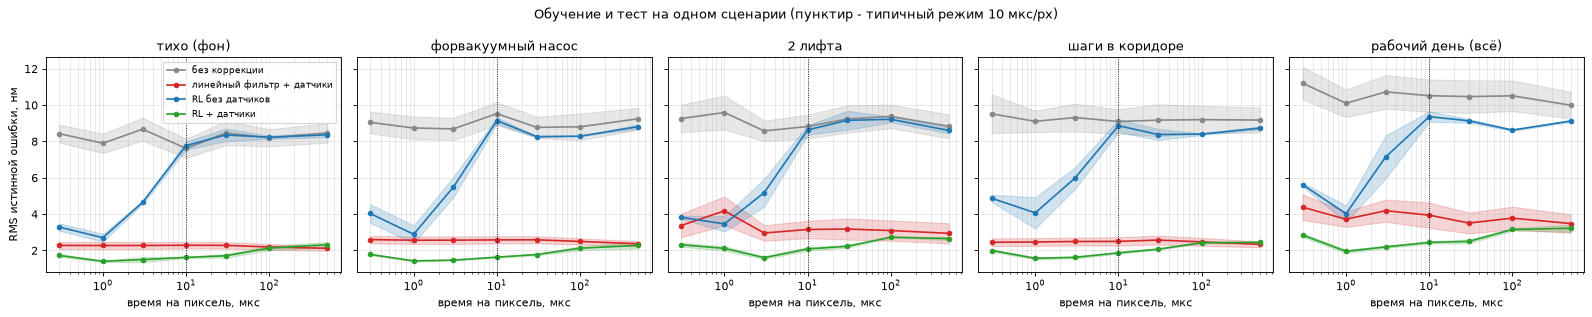

In [13]:
plots.dwell_by_scenario(df);

Главная картина видна сразу: **без датчиков RL работает только на быстрой развёртке** ($\leq$ 3 мкс/px),
а начиная с 10 мкс/px почти не отличается от отсутствия коррекции. **С датчиками** ошибка
1.4-3.2 нм при любом dwell, то есть меньше пикселя.

## 6. Проверка гипотез

### H1. Датчики помогают в типичном и медленном режимах

**Во сколько раз датчики снижают RMS (RL без датчиков / RL + датчики)**

| test               |   1 мкс/px |   10 мкс/px |   500 мкс/px |
|:-------------------|-----------:|------------:|-------------:|
| тихо (фон)         |       1.92 |        4.80 |         3.60 |
| форвакуумный насос |       2.03 |        5.60 |         3.87 |
| 2 лифта            |       1.64 |        4.14 |         3.24 |
| шаги в коридоре    |       2.59 |        4.74 |         3.57 |
| рабочий день (всё) |       2.06 |        3.83 |         2.83 |

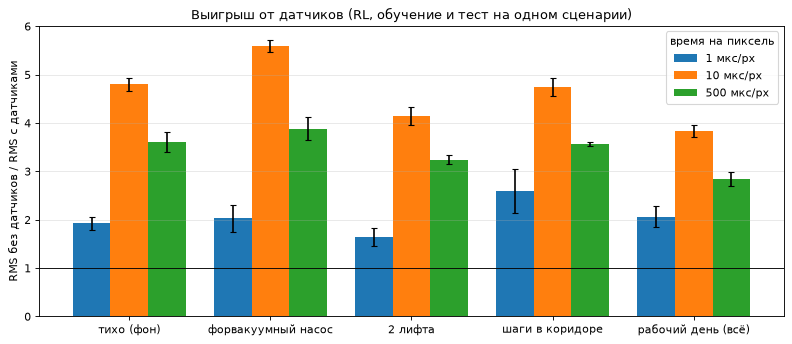

In [14]:
def gain(dw):
    """Во сколько раз датчики снижают RMS RL-агента при данном dwell, по сценариям."""
    # Отношение, а не разность: уровень помех в сценариях разный, а отношение сравнимо.
    t = d[np.isclose(d.dwell, dw)].groupby(["test", "method"]).rms_true.mean().unstack()
    return t.rl_nosens / t.rl_sens


g = pd.DataFrame({f"{dw * 1e6:g} мкс/px": gain(dw) for dw in (1e-6, 10e-6, 500e-6)})
show(g.reindex(plots.NAMES).rename(index=SC), "Во сколько раз датчики снижают RMS (RL без датчиков / RL + датчики)")
plots.sensor_gain(df);

In [15]:
t10 = table(d, 10e-6)
show(t10[[L["none"], L["rl_nosens"]]], "10 мкс/px: агент без датчиков против отсутствия коррекции, нм")

**10 мкс/px: агент без датчиков против отсутствия коррекции, нм**

| test               |   без коррекции |   RL без датчиков |
|:-------------------|----------------:|------------------:|
| тихо (фон)         |            7.62 |              7.77 |
| форвакуумный насос |            9.53 |              9.14 |
| 2 лифта            |            8.82 |              8.64 |
| шаги в коридоре    |            9.10 |              8.87 |
| рабочий день (всё) |           10.52 |              9.37 |

**H1 подтверждена.** При 10 мкс/px датчики снижают ошибку в 3.8-5.6 раза, при 500 мкс/px -
в 2.8-3.9 раза. Агент без датчиков при 10 мкс/px почти не лучше отсутствия коррекции. Механизм
тот, что предполагался: строка длится 20 мс = период сети, сетевая помеха во всех строках одна и
та же и по сдвигу строк не видна, а вибрация видна с опозданием на строку.

### H2. На быстрой развёртке выигрыш зависит от природы вибрации

In [16]:
t1 = d[np.isclose(d.dwell, 1e-6)].groupby(["test", "method"]).rms_true.mean().unstack()
h2 = pd.DataFrame({
    "RL без датчиков": t1.rl_nosens, "RL + датчики": t1.rl_sens,
    "выигрыш, раз": t1.rl_nosens / t1.rl_sens,
    'прибавка к "тихо" без датчиков': t1.rl_nosens - t1.rl_nosens["quiet"],
    'прибавка к "тихо" с датчиками': t1.rl_sens - t1.rl_sens["quiet"],
}).reindex(plots.NAMES).rename(index=SC)
show(h2, "1 мкс/px, нм")

**1 мкс/px, нм**

| test               |   RL без датчиков |   RL + датчики |   выигрыш, раз |   прибавка к "тихо" без датчиков |   прибавка к "тихо" с датчиками |
|:-------------------|------------------:|---------------:|---------------:|---------------------------------:|--------------------------------:|
| тихо (фон)         |              2.70 |           1.41 |           1.92 |                             0.00 |                            0.00 |
| форвакуумный насос |              2.89 |           1.43 |           2.03 |                             0.19 |                            0.02 |
| 2 лифта            |              3.46 |           2.11 |           1.64 |                             0.76 |                            0.71 |
| шаги в коридоре    |              4.07 |           1.57 |           2.59 |                             1.37 |                            0.16 |
| рабочий день (всё) |              4.02 |           1.95 |           2.06 |                             1.32 |                            0.54 |

**H2 подтверждена частично.**

* *Насос* - подтверждено: тональная вибрация предсказуема по изображению. Без датчиков агент на
  насосе почти так же хорош, как на тихом фоне, и датчики добавляют ровно столько же, сколько к фону.
* *Шаги* - подтверждено: импульсы по изображению видны поздно, датчики дают наибольший выигрыш.
* *Лифты* - не подтверждено: выигрыш наименьший, и лифты прибавляют к ошибке почти одинаково и
  без датчиков, и с ними. Вероятная причина - короткое окно наблюдения (8 мс), см. H4.

### H3. Перенос между гипотезами о вибрации

Каждый агент проверен на всех сценариях. Диагональ - свой сценарий, строки - сценарий обучения.

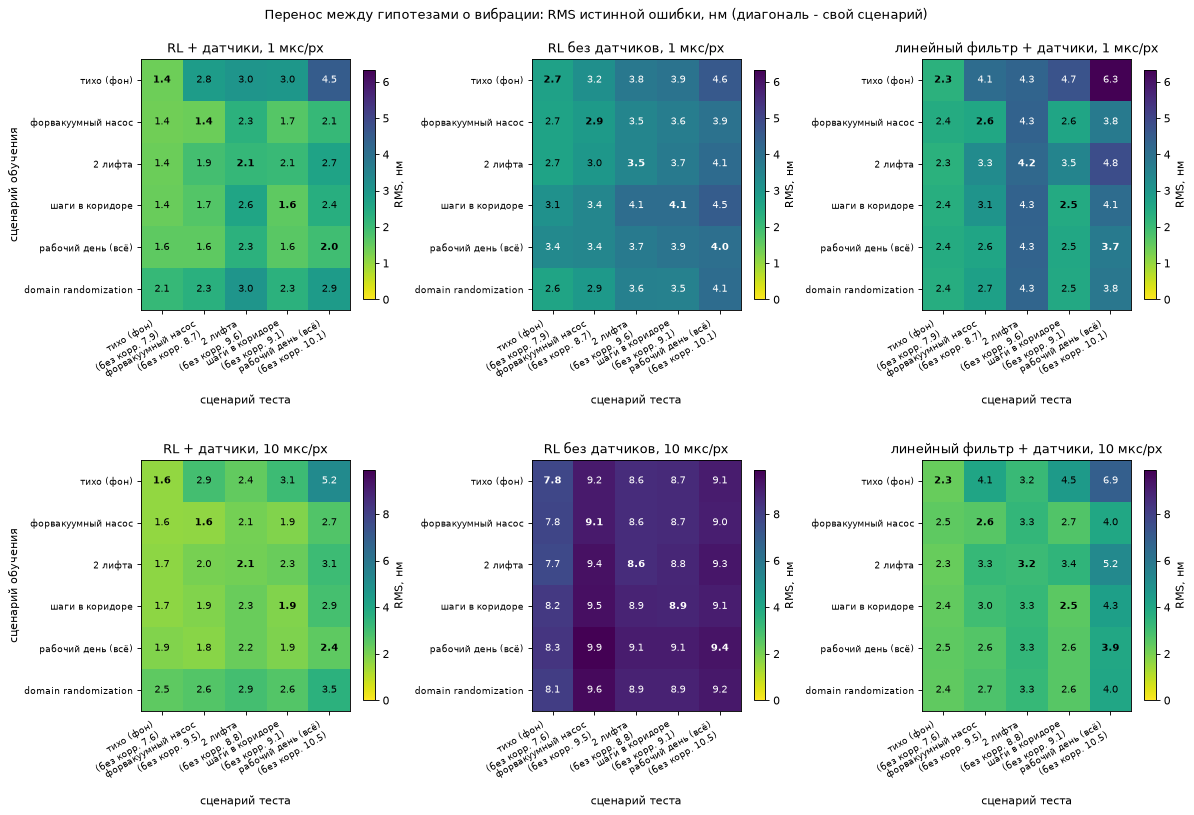

In [17]:
plots.matrices(df);

In [18]:
rows = []
for dw in (1e-6, 10e-6):
    mt = plots.matrix_table(df, "rl_sens", dw)
    spec = pd.Series(np.diag(mt.loc[plots.NAMES, plots.NAMES]), index=plots.NAMES)
    best = mt.loc[plots.NAMES].min()  # лучший результат на каждом тестовом сценарии среди специалистов
    rows.append({
        "dwell, мкс": dw * 1e6,
        '"тихо" на сценарии "рабочий день" / специалист': mt.loc["quiet", "building"] / spec["building"],
        '"рабочий день": худшее отставание от лучшего, %': 100 * (mt.loc["building"] / best - 1).max(),
    })
show(pd.DataFrame(rows).set_index("dwell, мкс"), "RL + датчики: перенос")

**RL + датчики: перенос**

|   dwell, мкс |   "тихо" на сценарии "рабочий день" / специалист |   "рабочий день": худшее отставание от лучшего, % |
|-------------:|-------------------------------------------------:|--------------------------------------------------:|
|         1.00 |                                             2.30 |                                             14.71 |
|        10.00 |                                             2.11 |                                             14.68 |

**H3 подтверждена.** Агент с "тихого" сценария на сценарии "рабочий день" теряет примерно в 2-2.3 раза
(всё равно вдвое лучше, чем без коррекции). Агент, обученный на сценарии "рабочий день", отстаёт от лучшего на любом
сценарии не больше чем на $\approx$ 15 %. Агент без датчиков переносится лучше (до 25 % потерь): всё, что он
умеет, - обратная связь по изображению, а она от гипотезы о вибрации зависит слабо.
**Практический вывод:** обучать нужно на сценарии со всеми ожидаемыми источниками.

### H4. RL против линейного фильтра

Сначала - как в основном эксперименте: оба видят 16 шагов (8 мс) истории датчиков.

In [19]:
h4 = {}
for sc in ("quiet", "building"):
    t = d[d.test == sc].groupby(["dwell", "method"]).rms_true.mean().unstack()
    h4[(SC[sc], "линейный фильтр")] = t.linear
    h4[(SC[sc], "RL + датчики")] = t.rl_sens
    h4[(SC[sc], "RL лучше на, %")] = 100 * (1 - t.rl_sens / t.linear)
h4 = pd.DataFrame(h4)
h4.index = [f"{x * 1e6:g}" for x in h4.index]
h4.index.name = "dwell, мкс"
show(h4, "RMS, нм")

**RMS, нм**

|   dwell, мкс |   ('тихо (фон)', 'линейный фильтр') |   ('тихо (фон)', 'RL + датчики') |   ('тихо (фон)', 'RL лучше на, %') |   ('рабочий день (всё)', 'линейный фильтр') |   ('рабочий день (всё)', 'RL + датчики') |   ('рабочий день (всё)', 'RL лучше на, %') |
|-------------:|------------------------------------:|---------------------------------:|-----------------------------------:|--------------------------------------------:|-----------------------------------------:|-------------------------------------------:|
|         0.30 |                                2.28 |                             1.73 |                              24.25 |                                        4.38 |                                     2.85 |                                      34.98 |
|         1.00 |                                2.27 |                             1.41 |                              38.19 |                                        3.72 |                                     1.95 |                                      47.58 |
|         3.00 |                                2.28 |                             1.50 |                              34.19 |                                        4.19 |                                     2.20 |                                      47.56 |
|        10.00 |                                2.29 |                             1.62 |                              29.22 |                                        3.95 |                                     2.44 |                                      38.08 |
|        30.00 |                                2.28 |                             1.71 |                              25.08 |                                        3.51 |                                     2.50 |                                      28.80 |
|       100.00 |                                2.19 |                             2.13 |                               2.92 |                                        3.78 |                                     3.16 |                                      16.51 |
|       500.00 |                                2.12 |                             2.32 |                              -9.65 |                                        3.48 |                                     3.22 |                                       7.45 |

RL + датчики лучше фильтра на 24-48 % при dwell $\leq$ 30 мкс. Дальше преимущество спадает:
на тихом фоне при 100 мкс/px остаётся около 3 %, при 500 мкс/px фильтр уже лучше на 10 %.
На сценарии "рабочий день" при 100 мкс/px ещё около 16 %, при 500 мкс/px около 7 %.
Раз преимущество убывает с ростом времени строки, его источник - обратная связь по сдвигу
строк (которой у фильтра нет), а не нелинейность политики.

**Проверка после эксперимента** ([`linear_memory.py`](../src/sem_beam_gym/linear_memory.py)): тот же
линейный фильтр, но с более длинной историей датчиков (вне среды, без инерции катушки), $\approx$ 30 с:

In [20]:
mem = linear_memory.main()
tab = mem.pivot(index="scenario", columns="hist_ms", values="rms_nm")
tab.columns = [f"{c:g} мс" for c in tab.columns]
tab["RL + датчики, 10 мкс"] = table(d, 10e-6)[L["rl_sens"]].rename(index={v: k for k, v in SC.items()})
show(tab.reindex(plots.NAMES).rename(index=SC), "RMS линейного фильтра в зависимости от длины истории, нм")

quiet done
footsteps done
pump done
elevators done
building done
hist_steps   16    32    64    128
scenario                          
building    4.34  3.25  2.02  1.08
elevators   3.36  2.53  1.70  1.03
footsteps   2.52  1.89  1.32  0.92
pump        2.58  1.92  1.33  0.92
quiet       2.27  1.77  1.25  0.90


**RMS линейного фильтра в зависимости от длины истории, нм**

| scenario           |   8 мс |   16 мс |   32 мс |   64 мс |   RL + датчики, 10 мкс |
|:-------------------|-------:|--------:|--------:|--------:|-----------------------:|
| тихо (фон)         |   2.27 |    1.77 |    1.25 |    0.90 |                   1.62 |
| форвакуумный насос |   2.58 |    1.92 |    1.33 |    0.92 |                   1.63 |
| 2 лифта            |   3.36 |    2.53 |    1.70 |    1.03 |                   2.08 |
| шаги в коридоре    |   2.52 |    1.89 |    1.32 |    0.92 |                   1.87 |
| рабочий день (всё) |   4.34 |    3.25 |    2.02 |    1.08 |                   2.44 |

**H4 в исходной форме опровергнута, но её суть верна.** С окном 64 мс классический линейный
фильтр в 1.8-2.3 раза лучше RL-агента ($\approx$ 1 нм против 1.6-2.4 нм). Причина физическая:
мода колонны 110 Гц с $\zeta = 0.05$ затухает за $1/(\zeta \omega) \approx 30$ мс, и 8 мс истории не хватает, чтобы
восстановить её состояние. **Узкое место - окно наблюдения, а не тип регулятора.** Для установки
это значит: первым шагом - линейный компенсатор с памятью $\geq$ 64 мс. RL - как надстройка над ним.

### H5. Domain randomization

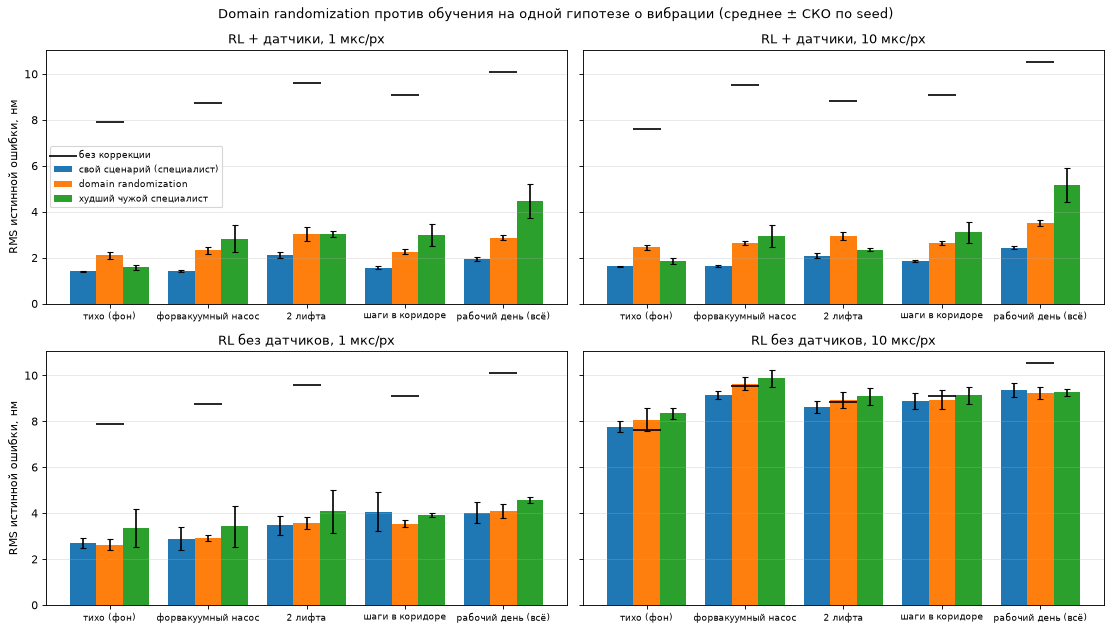

In [21]:
plots.dr_vs_specialist(df);

In [22]:
rows = []
for dw in (1e-6, 10e-6):
    mt = plots.matrix_table(df, "rl_sens", dw)
    for sc in plots.NAMES:
        foreign = mt.loc[[t for t in plots.NAMES if t != sc], sc]
        rows.append({"тест": SC[sc], "dwell, мкс": dw * 1e6, "специалист": mt.loc[sc, sc],
                     "DR": mt.loc["randomized", sc],
                     "DR хуже специалиста, %": 100 * (mt.loc["randomized", sc] / mt.loc[sc, sc] - 1),
                     "худший чужой": foreign.max(), '"рабочий день"': mt.loc["building", sc]})
show(pd.DataFrame(rows).set_index(["тест", "dwell, мкс"]), "RL + датчики, RMS, нм")

**RL + датчики, RMS, нм**

|                              |   специалист |   DR |   DR хуже специалиста, % |   худший чужой |   "рабочий день" |
|:-----------------------------|-------------:|-----:|-------------------------:|---------------:|-----------------:|
| ('тихо (фон)', 1.0)          |         1.41 | 2.10 |                    49.27 |           1.58 |             1.58 |
| ('форвакуумный насос', 1.0)  |         1.43 | 2.32 |                    62.79 |           2.83 |             1.57 |
| ('2 лифта', 1.0)             |         2.11 | 3.03 |                    43.27 |           3.04 |             2.26 |
| ('шаги в коридоре', 1.0)     |         1.57 | 2.27 |                    44.40 |           2.99 |             1.62 |
| ('рабочий день (всё)', 1.0)  |         1.95 | 2.87 |                    47.13 |           4.49 |             1.95 |
| ('тихо (фон)', 10.0)         |         1.62 | 2.45 |                    51.52 |           1.85 |             1.85 |
| ('форвакуумный насос', 10.0) |         1.63 | 2.64 |                    61.36 |           2.95 |             1.76 |
| ('2 лифта', 10.0)            |         2.08 | 2.94 |                    41.14 |           2.35 |             2.24 |
| ('шаги в коридоре', 10.0)    |         1.87 | 2.63 |                    40.77 |           3.11 |             1.92 |
| ('рабочий день (всё)', 10.0) |         2.44 | 3.52 |                    43.97 |           5.16 |             2.44 |

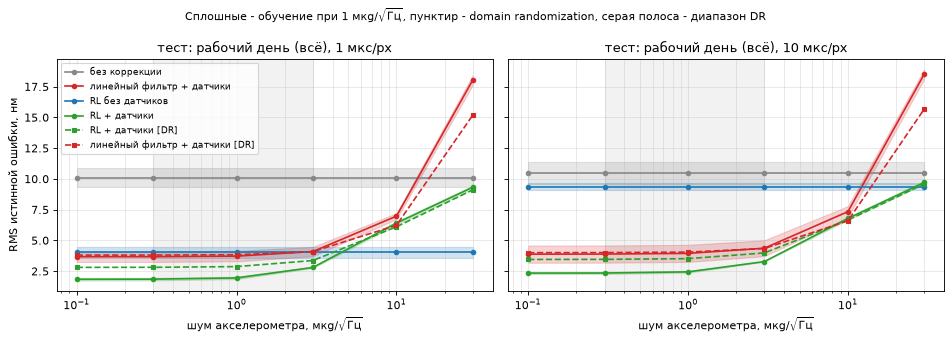

In [23]:
plots.acc_noise(df);

**H5 не подтверждена.**

* DR проигрывает специалисту на 41-63 %, а не на $\leq$ 15 %.
* Худшего "чужого" специалиста DR обходит только там, где худший - агент с "тихого" сценария.
  агенту, обученному на сценарии "рабочий день", он уступает на всех тестовых сценариях.
* К шуму акселерометра DR устойчивее лишь относительно. На участке 0.3-3 мкg/$\sqrt{Гц}$
  при 1 мкс/px ошибка DR растёт на 20 %, а у агента со сценария "рабочий день" - на 51 %.
  При 10 мкс/px это 15 % против 40 %. В абсолютных числах DR хуже на всём этом диапазоне.
* Без датчиков DR-агент не хуже специалистов - проигрывает именно политика, использующая датчики.

Альтернативные объяснения (сформулированы после результата, не проверены):  
1. Тестовые сценарии имеют номинальную физику, и DR платит за устойчивость, которую тест не измеряет.
2. По длине истории 8 мс частоту колонны не определить, и политика усредняется по 80-140 Гц, однако 
линейный фильтр с DR почти не теряет, так что RL с DR потерял именно своё преимущество над
фильтром.
3. Задача с DR труднее для PPO, а наблюдения не нормализуются под меняющийся шум датчиков.

**Требование к датчику** (график выше): до 1 мкg/$\sqrt{Гц}$ ошибка почти не зависит от шума. При 1 мкс/px
датчики теряют смысл около 5 мкg/$\sqrt{Гц}$, при 10 мкс/px - около 30 мкg/$\sqrt{Гц}$. RL деградирует мягко,
а линейный фильтр при сильном шуме становится хуже отсутствия коррекции. Нужен акселерометр
$\leq$ 1 мкg/$\sqrt{Гц}$ - сейсмический/пьезо, не дешёвый MEMS.

### Дополнительно: что видно на снимке и сильные события

In [24]:
d2 = d.assign(frac_pct=100 * d.frac_gt_1px)
show(table(d2, 10e-6, "rms_jitter"), "Видимый межстрочный сдвиг (RMS), нм, 10 мкс/px")
show(table(d2, 10e-6, "frac_pct"), "Доля времени с ошибкой > 1 px, %, 10 мкс/px")

**Видимый межстрочный сдвиг (RMS), нм, 10 мкс/px**

| test               |   без коррекции |   линейный фильтр + датчики |   RL без датчиков |   RL + датчики |
|:-------------------|----------------:|----------------------------:|------------------:|---------------:|
| тихо (фон)         |            2.35 |                        1.98 |              1.69 |           1.07 |
| форвакуумный насос |            4.83 |                        2.48 |              2.09 |           1.16 |
| 2 лифта            |            3.46 |                        2.76 |              1.95 |           1.37 |
| шаги в коридоре    |            3.66 |                        2.14 |              2.48 |           1.29 |
| рабочий день (всё) |            6.78 |                        3.66 |              2.74 |           1.74 |

**Доля времени с ошибкой > 1 px, %, 10 мкс/px**

| test               |   без коррекции |   линейный фильтр + датчики |   RL без датчиков |   RL + датчики |
|:-------------------|----------------:|----------------------------:|------------------:|---------------:|
| тихо (фон)         |           55.22 |                        3.38 |             56.19 |           0.97 |
| форвакуумный насос |           63.83 |                        5.87 |             64.67 |           0.99 |
| 2 лифта            |           60.02 |                       12.73 |             59.08 |           3.15 |
| шаги в коридоре    |           62.90 |                        4.96 |             62.10 |           2.01 |
| рабочий день (всё) |           64.54 |                       18.54 |             61.66 |           5.97 |

* **Видимое и истинное расходятся.** На тихом фоне без коррекции истинная ошибка $\approx$ 7.6 нм, а видимый
  сдвиг строк $\approx$ 2.4 нм: почти всю ошибку даёт сеть, одинаковая во всех строках. Снимок выглядит
  ровным, но геометрически искажён (см. профиль искажения в разделе 7).
* **Агент без датчиков** уменьшает именно видимый сдвиг, но доля времени с ошибкой > 1 px остаётся
  $\approx$ 55-65 %: он исправляет только то, что видно по изображению.
* **Линейный фильтр** на событиях даёт тяжёлый хвост: на сценарии "рабочий день" доля выбросов в $\approx$ 3 раза выше, чем у RL.

Зависимость ошибки эпизода от силы вибрации в нём (рабочий день):

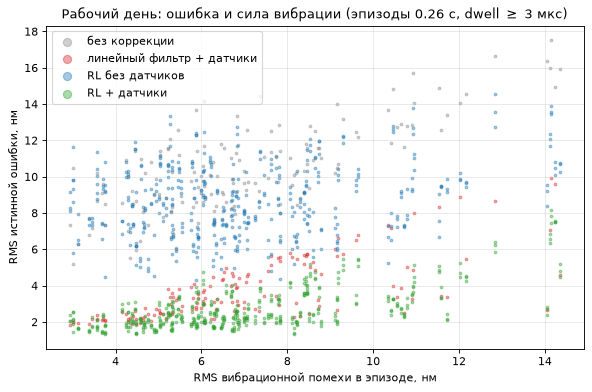

In [25]:
plots.events(df);

## 7. Поведение агентов

[`visualize.py`](../src/sem_beam_gym/visualize.py): все стратегии (агенты seed 0, обученные на сценарии "рабочий день")
снимают одну и ту же реализацию помех. Синтетический образец - решётка кругов. Пиксель снимается
в точке, куда в этот момент попал луч. (Время на отрисовку $\approx$ 25 с)

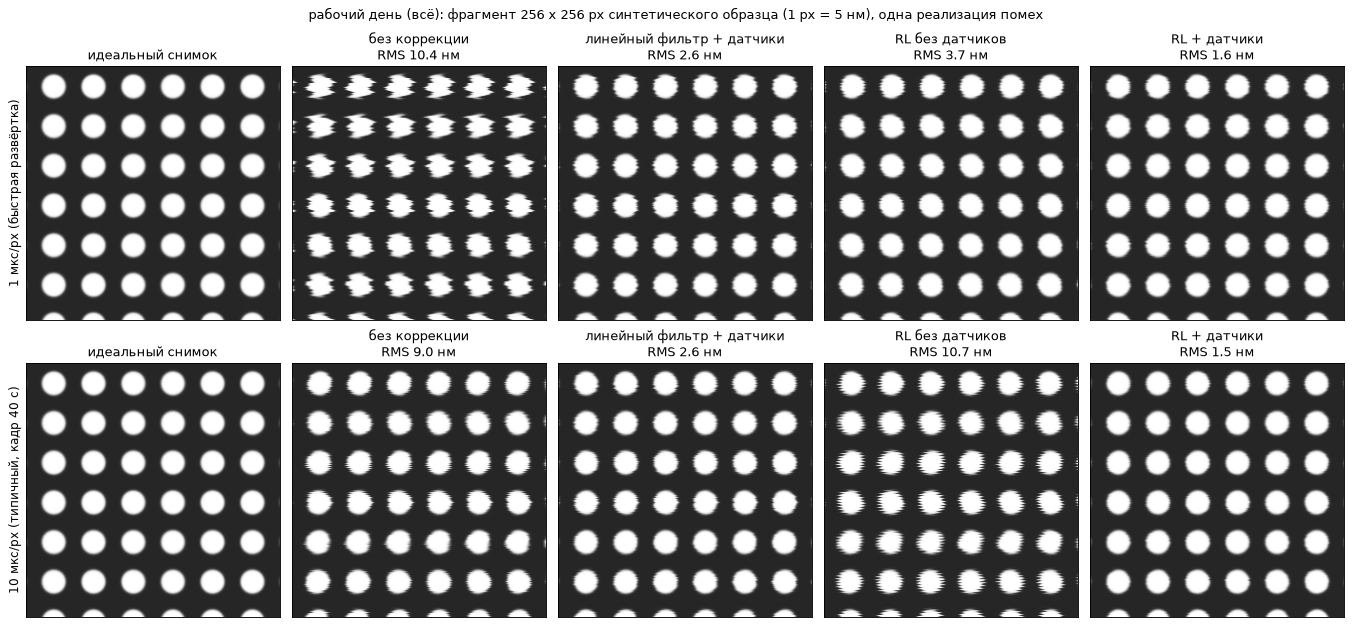

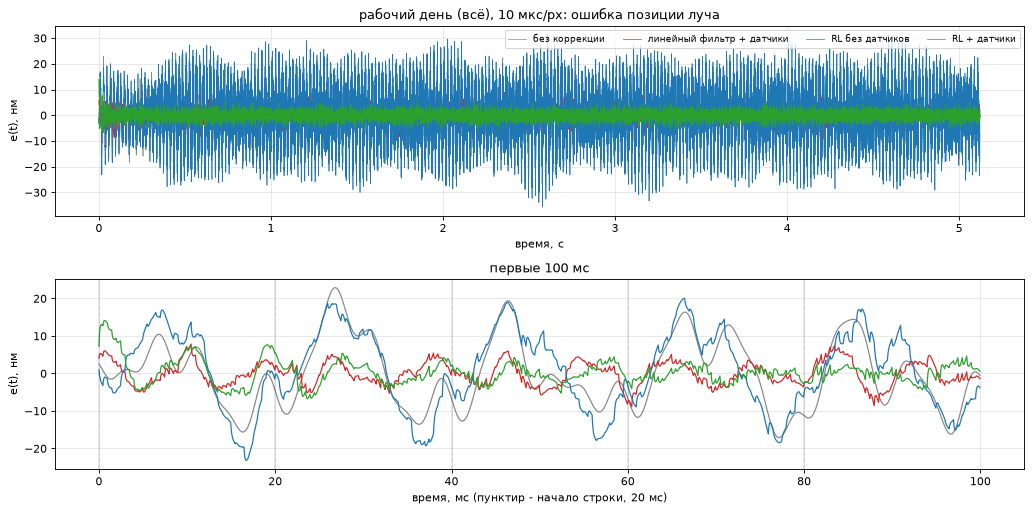

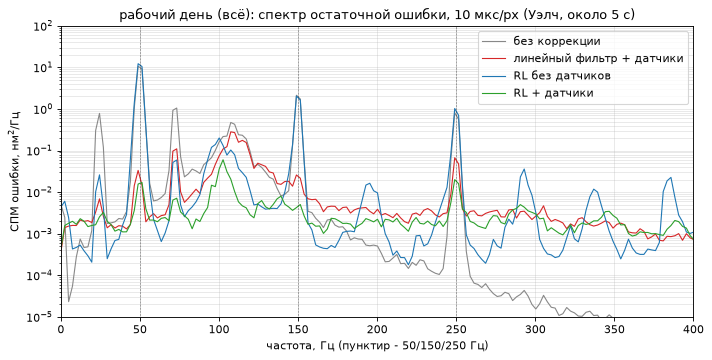

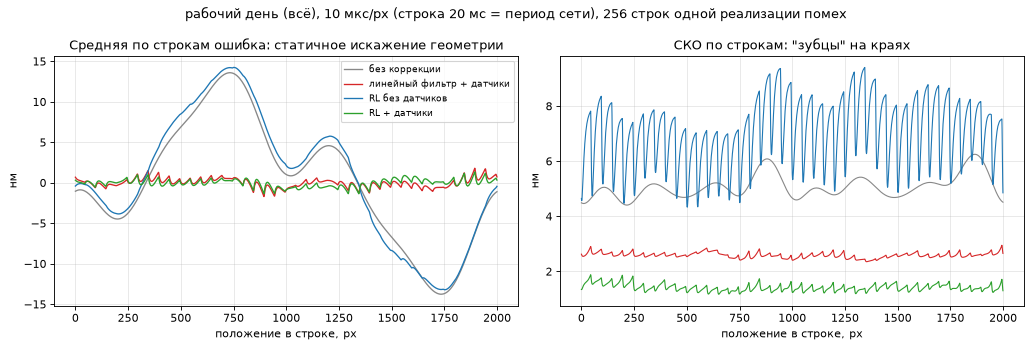

In [26]:
figs = visualize.visualize("building")

1. **Снимки.** Без коррекции - "зубцы" на быстрой развёртке и размытые края в типичном режиме.
   Агент без датчиков при 10 мкс/px почти ничего не исправляет. С датчиками снимок близок к идеальному.
2. **Ошибка во времени.** У агента без датчиков остаётся периодическая сетевая составляющая.
3. **Спектр.** Без датчиков остаются пики 50/150/250 Гц - сеть. С датчиками они подавлены.
4. **Профиль искажения.** Средняя по строкам ошибка - статичное искажение геометрии $\pm 8$ нм вдоль
   строки, которое глаз не видит как "зубцы". Убирается только с магнитометром.

## 8. Выводы

**Ответ на исследовательский вопрос.** В принятой модели помех магнитометр и акселерометр **реально
повышают качество снимка**: в типичном режиме 10 мкс/px RMS ошибки падает с 7.6-10.5 нм до 1.6-2.4 нм,
то есть ниже 1 px. Без датчиков в этом режиме не помогает ничего: сетевая помеха по изображению
не видна. Но выигрыш даёт прежде всего **сам сигнал датчиков, а не RL**: классический линейный
компенсатор с достаточной памятью (64 мс) справляется лучше RL-агента с окном 8 мс. RL
полезен там, где нужно совместить датчики с обратной связью по изображению (быстрая развёртка).

| Гипотеза | Итог |
|---|---|
| H1: датчики помогают при 10 мкс/px и медленнее | подтверждена: в 3.8-5.6 раза |
| H2: выигрыш зависит от природы вибрации | частично: насос и шаги - да, лифты - нет |
| H3: перенос между сценариями | подтверждена: "тихо" теряет в 2.1-2.3 раза, "рабочий день" - $\leq$ 15 % от лучшего |
| H4: RL $\approx$ линейный фильтр | опровергнута: RL лучше фильтра с тем же окном, но фильтр с окном 64 мс лучше RL |
| H5: domain randomization | не подтверждена: проигрыш специалисту 41-63 % |

**Практические рекомендации для установки:** 
1. ставить датчики имеет смысл, если основной
режим $\geq$ 10 мкс/px
2. акселерометр $\leq$ 1 мкg/$\sqrt{Гц}$
3. начинать с линейного компенсатора с
памятью $\geq$ 64 мс
4. обучать (или подгонять) на сценарии, содержащем все ожидаемые источники

**Ограничения.** Помехи и связь датчиков с лучом - модель, а не измерения. Одна ось. Одна мода
колонны. Награда привилегированная (на установке нужна калибровка или наблюдаемая награда).
Окно наблюдения 8 мс для всех методов. Эпизод 0.256 с, поэтому редкие сильные события
недопредставлены. Все dwell $\geq$ 10 мкс в сетке дают строку, кратную периоду сети.

**Направление для развития:**
- RL с длинной историей (64-128 шагов) или рекуррентной политикой
- residual RL поверх линейного компенсатора
- тест с рандомизированной физикой колонны - честная проверка DR
- нормализация наблюдений для DR
- behavioral cloning / DAgger от линейного фильтра как эксперта